In [2]:
import uproot
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, peak_widths, savgol_filter
import pandas as pd
import h5py

plt.rcParams["figure.dpi"] = 150

In [3]:
def plot_with_peaks(
    data,
    n_bins,
    prominence=None,
    xlabel="",
    title="",
    xlims=None,
    savgol_window=None,
    savgol_strength=1.0,
    clip_counts=None,
    stacked=False,
    legend=None,
    bin_range=None
):
    if not stacked:
        signals = [data]
    else:
        signals = data

    bottom = np.zeros(n_bins)

    for signal in signals:
        counts, bins = np.histogram(signal, bins=n_bins, density=True, range=bin_range)
        if savgol_window is not None:
            background = savgol_filter(counts, window_length=savgol_window, polyorder=3)
            counts = counts - background * savgol_strength

        if clip_counts is not None:
            counts[counts > clip_counts] = clip_counts

        bin_width = np.diff(bins).mean()
        bin_centers = (bins[:-1] + bins[1:]) / 2.0
        height_scale = counts.max()

        plt.bar(bin_centers, counts, width=bin_width, align="center", bottom=bottom)
        plt.xlim(xlims)
        bottom += counts
        bottom = np.round(bottom, 10)
        if prominence is not None:
            peaks, props = find_peaks(counts, prominence=prominence)
            half_widths = peak_widths(counts, peaks)[0] * bin_width
            for x, y, half_width in zip(
                bin_centers[peaks], counts[peaks], half_widths
            ):
                plt.errorbar(
                    [x],
                    [y],
                    xerr=[half_width],
                    c="black",
                    fmt="",
                    capsize=5,
                    elinewidth=0.5,
                    capthick=0.5,
                )
                plt.annotate(
                    f"{x:.03f} ± {half_width:.03f} MeV",
                    (x, y + height_scale * 0.03),
                    ha="left",
                    fontsize=5,
                )

    plt.xlabel(xlabel)
    plt.ylabel("Density")
    # plt.ylim(ylims)
    plt.title(title)
    if legend is not None:
        plt.legend(legend)

    plt.show()

# HDF5

In [4]:
keys = [
    "E",
    "p_x",
    "p_y",
    "p_z",
    "x",
    "y",
    "z",
    "name",
    "creator",
    "time",
    "step",
    "trackID",
]

def decode(b):
    return b.decode("utf-8")

decode_v = np.vectorize(decode)

def get_df():
    dfs = []
    with h5py.File("archive/cry_all_1M.hdf5", "r") as f:
        for key in keys:
            data = f["default_ntuples"]["SecondaryGammas"][key]["pages"][()]
            if isinstance(data[0], bytes):
                data = decode_v(data)
                
            dfs.append(pd.DataFrame(data, columns=[key]))

    return pd.concat(dfs, axis=1)

In [5]:
df = get_df()
df

,E,p_x,p_y,p_z,x,y,z,name,creator,time,step,trackID
0,0.002986,0.730724,0.625888,-0.272592,-16707.433523,-24990.999095,-13267.714349,gamma,eBrem,96.123838,1,3509
1,0.003393,0.692965,-0.477826,-0.539891,-16526.572638,-24906.347137,-13155.659022,gamma,eBrem,95.392217,1,3521
2,0.032561,-0.694228,-0.582131,0.423287,-16523.198197,-24897.224840,-13154.663140,gamma,eBrem,95.367335,1,3526
3,0.002905,-0.967799,-0.250423,0.025560,-16501.925983,-24886.649382,-13157.502246,gamma,eBrem,95.269836,1,3516
4,0.999397,-0.973800,-0.199026,0.110008,-16501.917150,-24886.647580,-13157.502584,gamma,eBrem,95.877748,1,3515
...,...,...,...,...,...,...,...,...,...,...,...,...
101337952,0.011437,-0.115604,-0.030187,-0.992837,20640.926566,6706.801667,-258.844244,gamma,eBrem,2.704394,1,37
101337953,1.143708,-0.274384,-0.065535,-0.959384,20641.634544,6706.952569,-255.681411,gamma,eBrem,2.707354,1,36
101337954,0.060046,-0.413986,-0.078621,-0.906882,20645.172682,6708.182009,-245.094945,gamma,eBrem,2.686060,1,34
101337955,0.001720,0.621540,0.681668,0.386027,20641.296064,6707.445792,-253.587107,gamma,phot,2.686074,1,61


# CSV

In [84]:
df = pd.read_csv("archive/all_1M_15pc_soil.csv", comment="#", header=None)
df.columns = [
    "E",
    "p_x",
    "p_y",
    "p_z",
    "x",
    "y",
    "z",
    "creator",
    "time",
]
print(f"{df.shape[0]:,} gamma rays recorded")
df

22,434,603 gamma rays recorded


,E,p_x,p_y,p_z,x,y,z,creator,time
0,0.536261,-0.037551,-0.939272,0.341113,-19663.0,5816.40,-13126.6000,muMinusCaptureAtRest,755.217000
1,4.170130,-0.580028,-0.360563,0.730453,-19663.0,5816.40,-13126.6000,muMinusCaptureAtRest,756.534000
2,0.510999,0.725559,0.024164,0.687735,-19909.7,5662.18,-12814.7000,annihil,756.809000
3,0.510999,-0.725559,-0.024164,-0.687735,-19909.7,5662.18,-12814.7000,annihil,757.231000
4,0.693259,-0.213776,-0.904185,0.369796,-19663.0,5816.40,-13126.6000,muMinusCaptureAtRest,47.178200
...,...,...,...,...,...,...,...,...,...
22434598,1.052410,-0.168191,0.935717,-0.310074,-10066.4,-20908.20,-25.1441,eBrem,0.473888
22434599,0.510999,-0.535493,0.252848,0.805801,-19930.8,10203.20,-14.5245,annihil,0.368504
22434600,0.510999,0.535493,-0.252848,-0.805801,-19930.8,10203.20,-14.5245,annihil,0.369446
22434601,1.585130,0.903297,0.316723,0.289381,-18935.0,-8202.57,-387.7180,eBrem,1.902830


# Analysis

In [48]:
carbon_e_range = df["E"].between(4.2, 4.7)
carbon_e_zoom = df["E"].between(4.4379, 4.4381)
wide_e_range = df["E"].between(1.0, 10.0)
inelastic_creator = df["creator"] == "neutronInelastic"
shallow = df["z"].between(-200.0, 0.0)
upward = df["p_z"] > 0.0

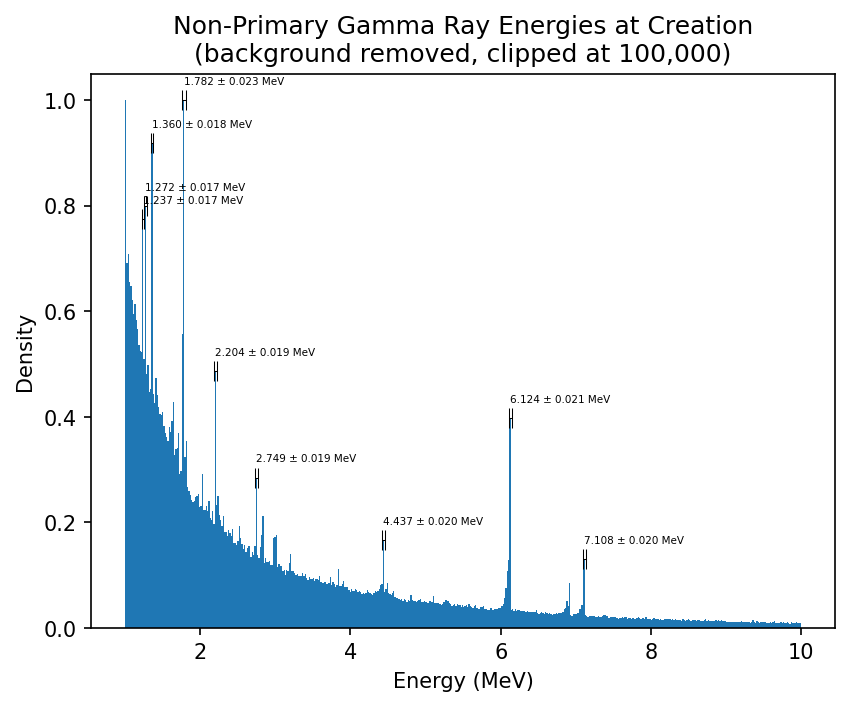

In [49]:
energies = df[wide_e_range & upward]["E"]
plot_with_peaks(
    data=energies,
    n_bins=512,
    prominence=0.1,
    xlabel="Energy (MeV)",
    title="Non-Primary Gamma Ray Energies at Creation\n(background removed, clipped at 100,000)",
    clip_counts=1.0,
)

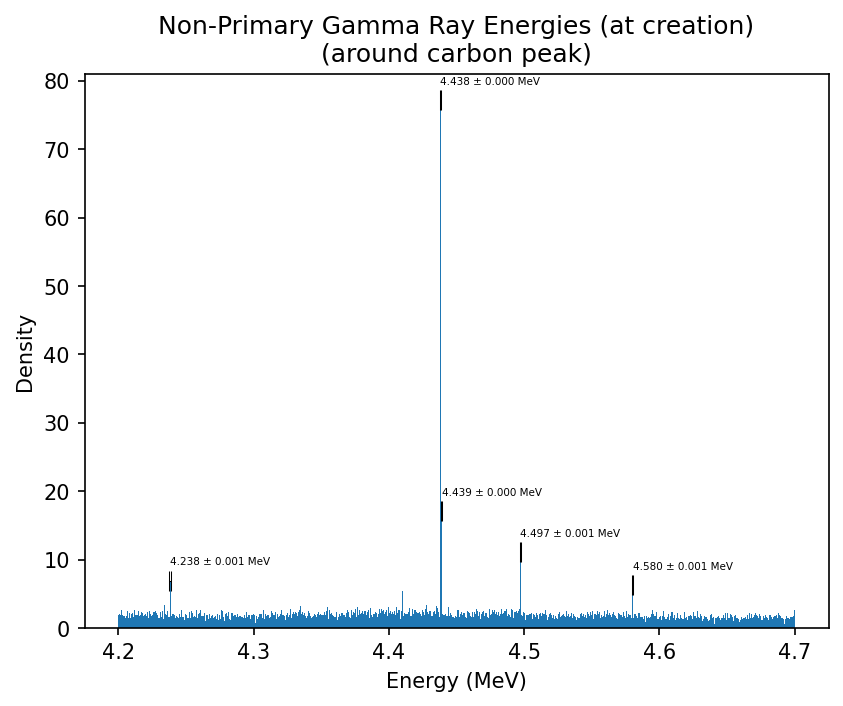

In [52]:
energies = df[carbon_e_range & upward]["E"]
plot_with_peaks(
    data=energies,
    n_bins=1024,
    prominence=5,
    xlabel="Energy (MeV)",
    title="Non-Primary Gamma Ray Energies (at creation)\n(around carbon peak)",
)

In [53]:
include_processes = lambda names: df["creator"].isin(names)
exclude_processes = lambda names: ~df["creator"].isin(names)

process_names, process_counts = np.unique(df["creator"], return_counts=True)
process_counts, process_names = zip(*sorted(zip(process_counts, process_names))[::-1])

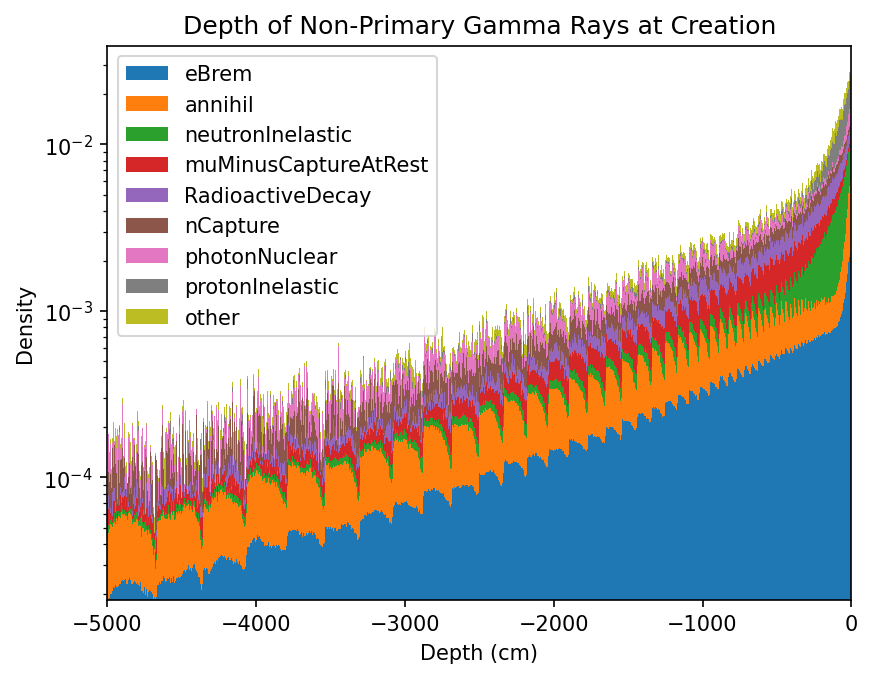

In [54]:
plt.yscale("log")
plot_with_peaks(
    data=[df[include_processes([name])]["z"] / 10 for name in process_names[:8]]
    + [df[exclude_processes(process_names[:8])]["z"] / 10],
    n_bins=1024,
    xlabel="Depth (cm)",
    title="Depth of Non-Primary Gamma Rays at Creation",
    xlims=(-5000, 0),
    stacked=True,
    legend=list(process_names[:8]) + ["other"],
    bin_range=(-5000, 0),
)

mean     -468.034985
median   -171.230000
std       738.181536
Name: z, dtype: float64


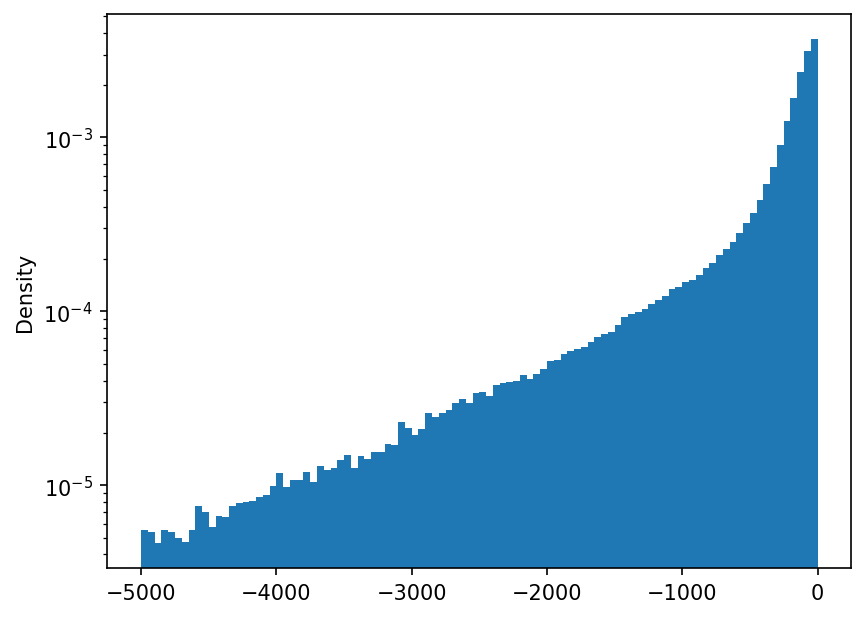

In [83]:
mctaggart = include_processes(["neutronInelastic", "nCapture", "RadioactiveDecay"])
print(df[mctaggart]["z"].aggregate(["mean", "median", "std"]) / 10)
plt.yscale("log")
plot_with_peaks(df[mctaggart]["z"] / 10, 100)

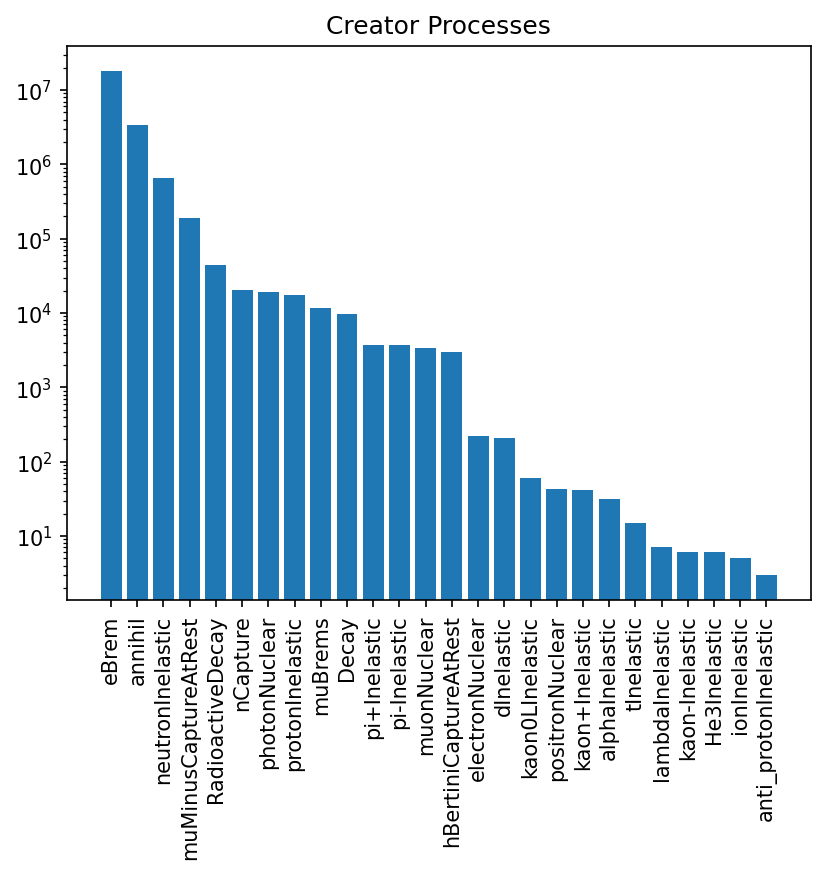

In [58]:
plt.yscale("log")
plt.bar(process_names, process_counts)
plt.xticks(rotation="vertical")
plt.title("Creator Processes")
plt.show()

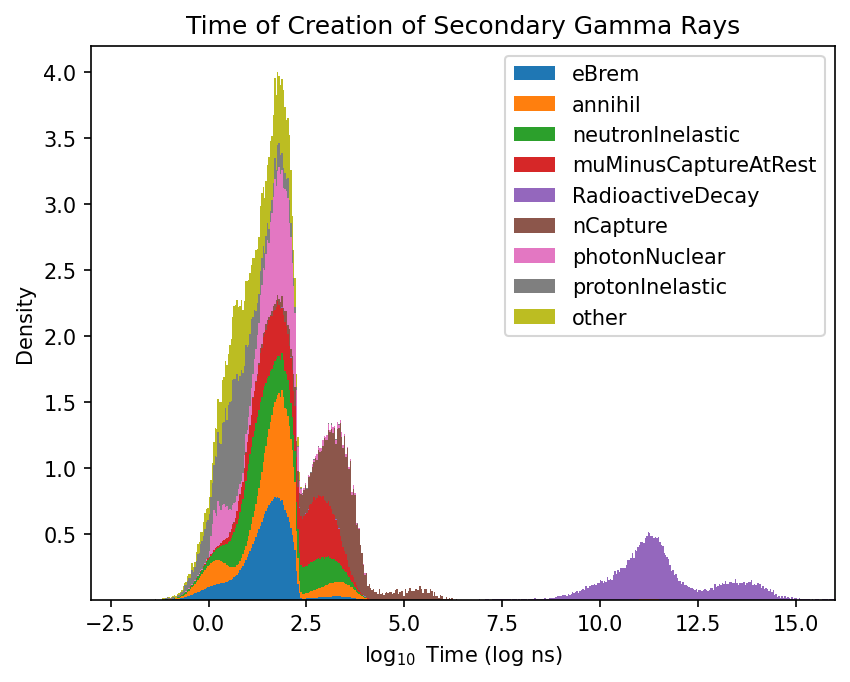

In [74]:
plot_with_peaks(
    data=[np.log10(df[include_processes([name])]["time"]) for name in process_names[:8]]
    + [np.log10(df[exclude_processes(process_names[:8])]["time"])],
    n_bins=512,
    title="Time of Creation of Secondary Gamma Rays",
    xlabel="$\\log_{10}$ Time (log ns)",
    stacked=True,
    legend=list(process_names[:8]) + ["other"],
    bin_range=(-3.0, 16.0),
    xlims=(-3.0, 16.0),
)

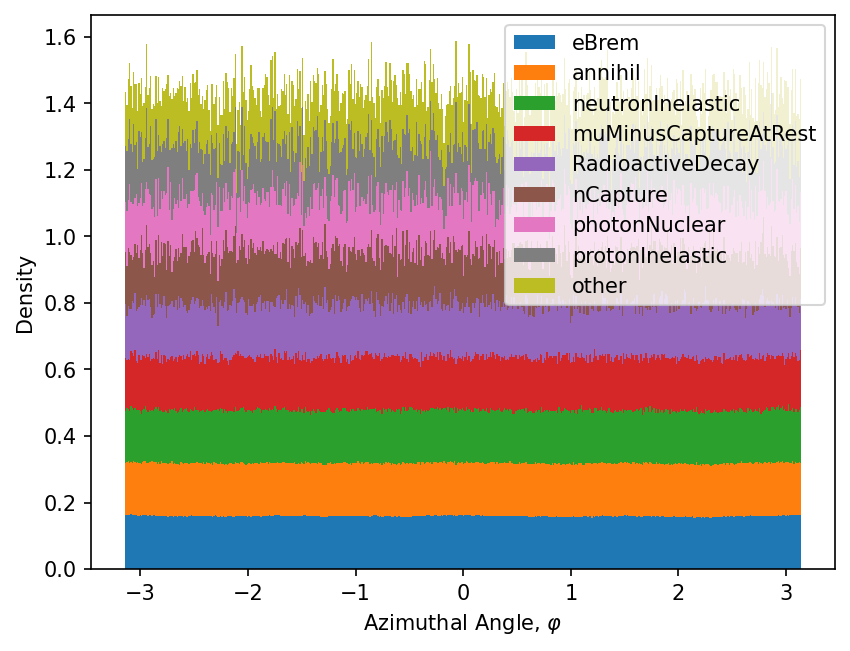

In [65]:
plot_with_peaks(
    [
        np.atan2(
            df[include_processes([name])]["p_x"], df[include_processes([name])]["p_y"]
        )
        for name in process_names[:8]
    ] + [np.atan2(
            df[exclude_processes(process_names[:8])]["p_x"], df[exclude_processes(process_names[:8])]["p_y"]
        )],
    512,
    xlabel="Azimuthal Angle, $\\varphi$",
    stacked=True,
    legend=list(process_names[:8]) + ["other"],
    bin_range=(-np.pi, np.pi)
)

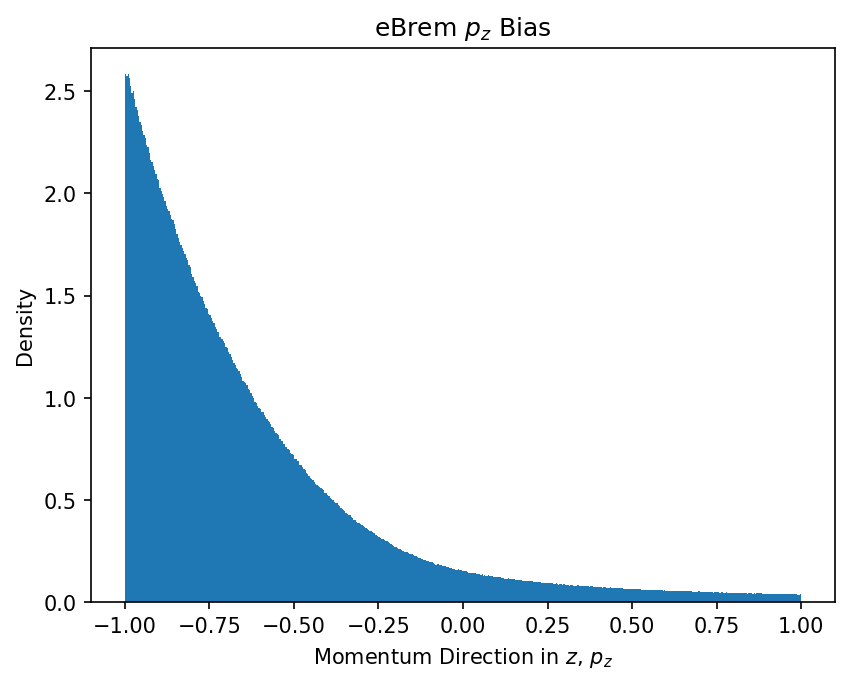

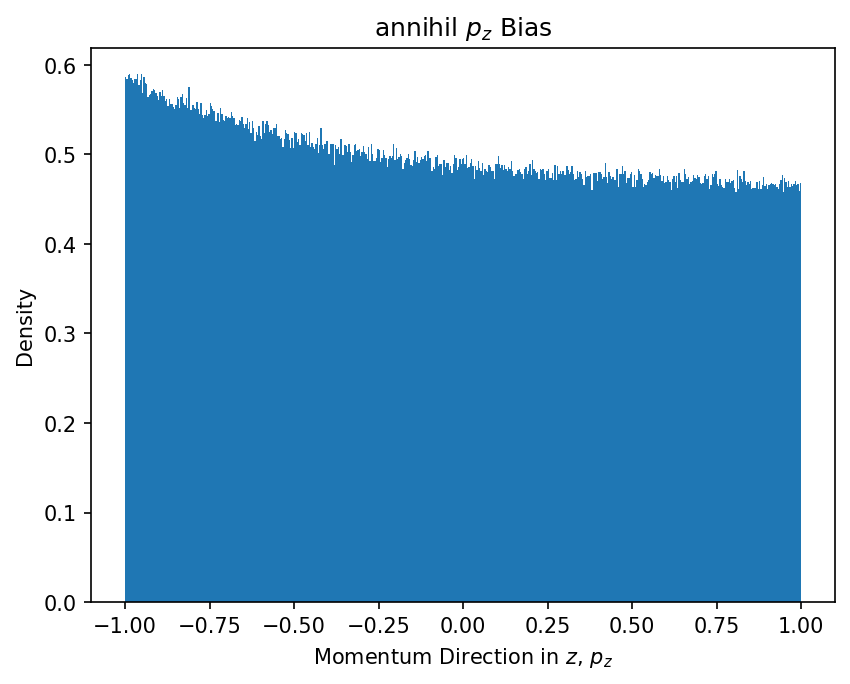

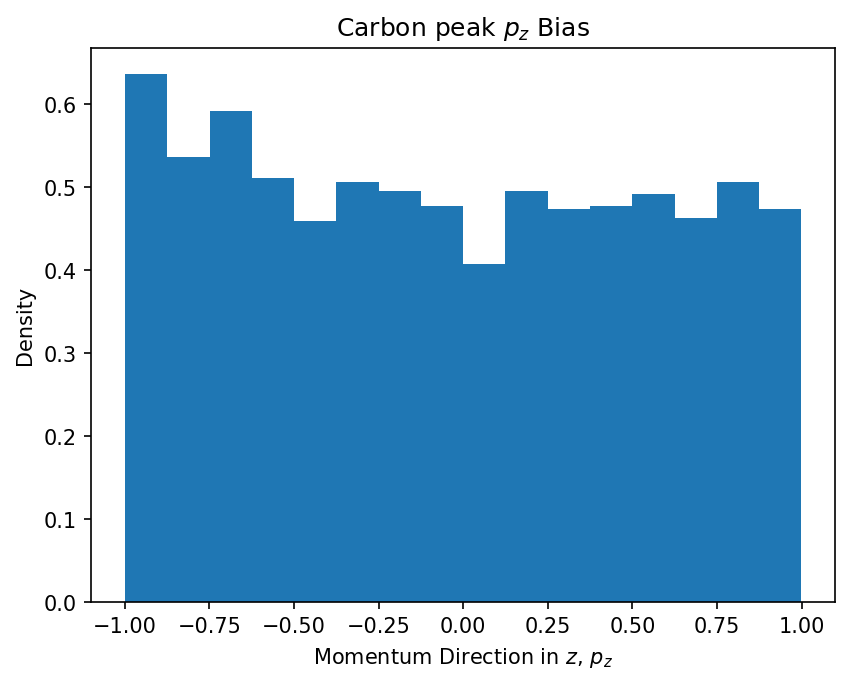

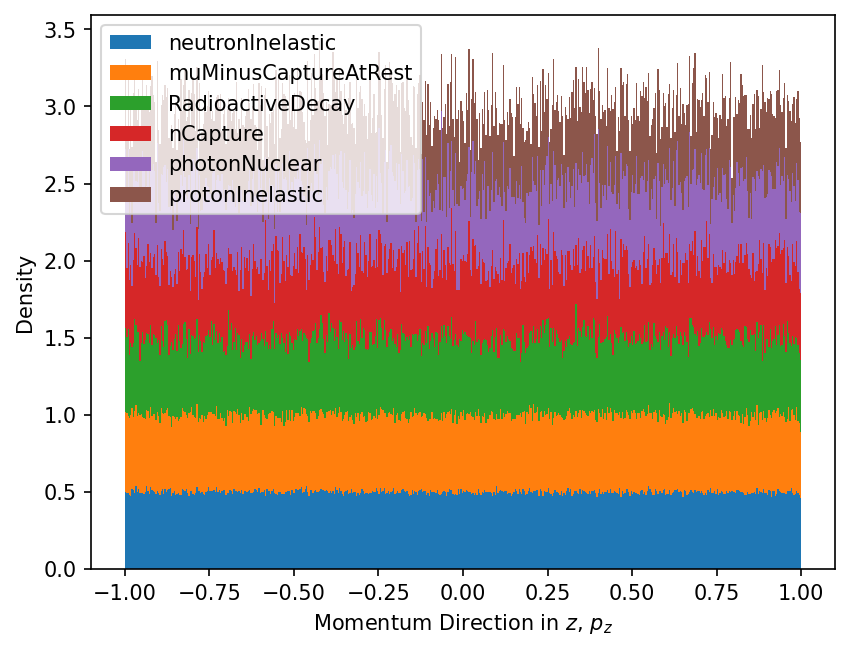

In [71]:
plot_with_peaks(
    df[include_processes(["eBrem"])]["p_z"], 512, xlabel="Momentum Direction in $z$, $p_z$", title="eBrem $p_z$ Bias"
)
plot_with_peaks(
    df[include_processes(["annihil"])]["p_z"], 512, xlabel="Momentum Direction in $z$, $p_z$", title="annihil $p_z$ Bias"
)
plot_with_peaks(
    df[carbon_e_zoom]["p_z"], 16, xlabel="Momentum Direction in $z$, $p_z$", title="Carbon peak $p_z$ Bias"
)
plot_with_peaks(
    [df[include_processes([name])]["p_z"] for name in process_names[2:8]],
    512,
    xlabel="Momentum Direction in $z$, $p_z$",
    stacked=True,
    legend=process_names[2:8],
    bin_range=(-1.0, 1.0)
)